# Tech Challenge Fase 1 - Case NPS Preditivo

Este notebook reúne a análise exploratória e a proposta de modelagem preditiva para o case de NPS do e-commerce. O objetivo foi entender quais gargalos da operação estão derrubando a nota de satisfação dos clientes e estruturar uma forma de agir antes que a nota baixa se concretize.

## 1. Entendimento do Negócio

**Qual problema de negócio está sendo resolvido?**
O e-commerce cresceu em volume, mas a experiência do cliente não acompanhou esse ritmo. Olhando para a base histórica, a nota média de NPS é de apenas 4,38 (mediana de 4,40) e cerca de 84,4% dos pedidos avaliados estão na faixa de detratores (nota menor que 7). Hoje a empresa só descobre essa insatisfação quando o cliente responde à pesquisa após o fim do processo. O problema central aqui é sair desse modelo reativo: descobrir exatamente o que na operação gera tanta insatisfação e usar os dados do pedido em andamento para prever quem tem alto risco de virar detrator antes mesmo da pesquisa ser enviada.

**Por que o NPS é importante para um e-commerce?**
No varejo online, trazer um cliente novo custa caro (CAC alto) e a primeira compra quase sempre tem margem apertada por conta de descontos promocionais (média de R$ 29,75 na base) e custo de frete. O NPS acaba sendo um termômetro direto de retenção: se o cliente tem uma experiência ruim logo na entrega ou no atendimento, ele simplesmente não volta a comprar e a conta do CAC não fecha.

**Quais áreas se beneficiam desses insights?**
- **Logística e Transporte:** Consegue enxergar o peso real do atraso na entrega (`delivery_delay_days`, correlação de -0,60 com o NPS) para renegociar SLAs com transportadoras ou ajustar a promessa de prazo no site.
- **Atendimento (SAC / CX):** Pode usar os dados de reclamações (`complaints_count`) e tempo de resolução (`resolution_time_days`) para criar filas de prioridade, evitando que o cliente precise entrar em contato várias vezes.
- **Produto e Operações:** Ajuda a investigar o motivo raiz das reclamações (produto avariado, erro de separação, cadastro divergente).
- **CRM e Comercial:** Pode acionar réguas automáticas de retratação (cupom, frete grátis ou contato ativo) assim que o pedido apresentar falhas operacionais.

**Reflexão: Impacto em Recompra, Boca a Boca e Market Share**
Cruzando o NPS com a variável de recompra em 30 dias (`repeat_purchase_30d`) na própria base, a relação financeira fica muito clara:
- Entre os **Detratores (nota < 7)**, a taxa de recompra em 30 dias foi de **0%**.
- Entre os **Neutros (7 a 8,9)**, **38,4%** voltaram a comprar.
- Entre os **Promotores (9 a 10)**, **100%** fizeram nova compra em até 30 dias (na base, só quem deu nota a partir de 8,0 voltou a comprar).

Além da perda direta de receita recorrente, o detrator gera um boca a boca negativo pesado em sites como o Reclame Aqui e redes sociais, aumentando o custo de aquisição. No médio prazo, operar com mais de 80% de detratores significa perder market share para players que entregam no prazo combinado.

**Indicadores de mercado que complementariam a análise**
Para enriquecer esse diagnóstico no dia a dia, valeria acompanhar:
- **OTIF (On-Time In-Full):** percentual de pedidos entregues no prazo e sem avarias/itens faltantes.
- **FCR (First Contact Resolution):** taxa de problemas resolvidos já no primeiro contato com o SAC.
- **Reputação externa:** nota e índice de solução no Reclame Aqui em comparação com os concorrentes diretos.
- **CES (Customer Effort Score):** para medir o tamanho da burocracia que o cliente enfrenta quando precisa trocar ou reclamar de um pedido.

## 2. Definição da Target

**Qual variável representa a satisfação do cliente e por que foi escolhida?**
A variável escolhida é a `nps_score` (que na base varia de 0,0 a 10,0). Para facilitar a leitura de negócio e seguir a metodologia de mercado, agrupamos as notas nas três faixas clássicas:
- **Detratores:** nota < 7,0 (ou <= 6,0 na escala inteira tradicional)
- **Neutros:** nota entre 7,0 e 8,9
- **Promotores:** nota >= 9,0

Ela foi escolhida porque resume a percepção final do cliente sobre toda a jornada (compra, entrega e pós-venda) e tem relação direta com o indicador de recompra em 30 dias.

**Em que momento da jornada essa informação é coletada?**
Logo após o encerramento da jornada do pedido — ou seja, depois que a entrega foi finalizada e eventuais chamados no atendimento foram concluídos.

**Existe algum risco de usar essa variável de forma inadequada?**
Sim, dois pontos exigem bastante cuidado:
1. **Vazamento de dados (Data Leakage) no modelo preditivo:** Na base temos colunas como `repeat_purchase_30d` (se o cliente comprou de novo em 30 dias) e `csat_internal_score` (avaliação interna de fechamento). Essas informações só existem *depois* ou *junto* com o fim da jornada. Se colocarmos essas duas variáveis como entrada do modelo, ele vai acertar muito no treino, mas não vai servir na prática quando quisermos prever o NPS com o pedido ainda em andamento. Por isso, elas foram retiradas da etapa de modelagem.
2. **Viés de resposta e escala contínua:** Pesquisas de NPS normalmente têm mais respostas de clientes muito irritados ou muito satisfeitos. Além disso, como a coluna `nps_score` veio com casas decimais (ex: 6,9), é importante deixar claro se o corte de detrator considera `< 7,0` (84,36% da base) ou `<= 6,0` (74,04% da base). Aqui seguimos com `< 7,0` para não deixar notas entre 6,1 e 6,9 num "limbo" fora das faixas.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    GradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, roc_auc_score, classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (11, 5)

# Carregamento do CSV (verifica tanto na pasta data/ quanto no diretório atual)
caminho_csv = '../data/desafio_nps_fase_1.csv' if os.path.exists('../data/desafio_nps_fase_1.csv') else 'desafio_nps_fase_1.csv'
df = pd.read_csv(caminho_csv)

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print(f"Valores nulos: {df.isnull().sum().sum()}")
df.head()

Linhas: 2500 | Colunas: 19
Valores nulos: 0


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [ ]:
# Checagem rápida das estatísticas da base
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
customer_id,2500.0,1250.50,721.83,1.00,625.75,1250.50,1875.25,2500.00
customer_age,2500.0,43.40,14.89,18.00,31.00,43.00,56.00,69.00
customer_tenure_months,2500.0,61.32,34.48,1.00,31.00,62.00,91.00,119.00
order_id,2500.0,51250.50,721.83,50001.00,50625.75,51250.50,51875.25,52500.00
order_value,2500.0,434.26,289.77,7.76,220.24,375.52,577.29,1983.81
items_quantity,2500.0,3.47,1.69,1.00,2.00,3.00,5.00,6.00
discount_value,2500.0,29.75,29.23,0.02,8.88,20.94,40.83,230.33
payment_installments,2500.0,6.00,3.16,1.00,3.00,6.00,9.00,11.00
delivery_time_days,2500.0,8.02,3.77,2.00,5.00,8.00,11.00,14.00
delivery_delay_days,2500.0,2.19,1.45,0.00,1.00,2.00,3.00,8.00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Criando a classificação de NPS e uma flag binária para facilitar o cálculo de taxa de detratores
def classificar_nps(nota):
    if nota < 7.0:
        return 'Detrator'
    elif nota < 9.0:
        return 'Neutro'
    return 'Promotor'

df['faixa_nps'] = df['nps_score'].apply(classificar_nps)
df['is_detrator'] = (df['nps_score'] < 7.0).astype(int)

resumo_faixas = df.groupby('faixa_nps').agg(
    qtd_clientes=('customer_id', 'count'),
    nps_medio=('nps_score', 'mean'),
    taxa_recompra_30d=('repeat_purchase_30d', lambda x: x.mean() * 100)
).loc[['Detrator', 'Neutro', 'Promotor']]

resumo_faixas['percentual_base'] = (resumo_faixas['qtd_clientes'] / len(df) * 100).round(2)
resumo_faixas = resumo_faixas[['qtd_clientes', 'percentual_base', 'nps_medio', 'taxa_recompra_30d']].round(2)

nps_consolidado = resumo_faixas.loc['Promotor', 'percentual_base'] - resumo_faixas.loc['Detrator', 'percentual_base']
print(f"NPS Consolidado da base (% Promotores - % Detratores): {nps_consolidado:.2f}")
resumo_faixas

NPS Consolidado da base (% Promotores - % Detratores): -79.96


,qtd_clientes,percentual_base,nps_medio,taxa_recompra_30d
faixa_nps,,,,
Detrator,2109,84.36,3.65,0.00
Neutro,281,11.24,7.79,38.43
Promotor,110,4.40,9.61,100.00


## 3. Análise Exploratória dos Dados (EDA)

Para entender o que realmente puxa a nota para baixo, comecei olhando a correlação das variáveis numéricas com o `nps_score` e, na sequência, abri o comportamento das variáveis operacionais (atraso, reclamações, contatos no SAC e tempo de resolução) e de perfil do cliente.

In [ ]:
colunas_num = df.select_dtypes(include=[np.number]).columns.drop(['customer_id', 'order_id', 'is_detrator'])
corr_nps = df[colunas_num].corr()['nps_score'].sort_values(ascending=False)

corr_nps.to_frame(name='correlacao_nps').round(3)

,correlacao_nps
nps_score,1.000
repeat_purchase_30d,0.570
csat_internal_score,0.564
order_value,0.037
delivery_attempts,0.028
discount_value,0.025
payment_installments,0.024
items_quantity,0.011
delivery_time_days,0.001
customer_tenure_months,-0.010


In [ ]:
# Avaliando o comportamento do NPS conforme aumentam os dias de atraso na entrega
analise_atraso = df.groupby('delivery_delay_days').agg(
    pedidos=('order_id', 'count'),
    nps_medio=('nps_score', 'mean'),
    pct_detratores=('is_detrator', lambda x: x.mean() * 100),
    pct_recompra=('repeat_purchase_30d', lambda x: x.mean() * 100)
).round(2)

print("Impacto dos dias de atraso (delivery_delay_days):")
display(analise_atraso)

# Avaliando o impacto da quantidade de reclamações
analise_reclamacoes = df.groupby('complaints_count').agg(
    pedidos=('order_id', 'count'),
    nps_medio=('nps_score', 'mean'),
    pct_detratores=('is_detrator', lambda x: x.mean() * 100),
    pct_recompra=('repeat_purchase_30d', lambda x: x.mean() * 100)
).round(2)

print("\nImpacto do número de reclamações (complaints_count):")
display(analise_reclamacoes)

Impacto dos dias de atraso (delivery_delay_days):


,pedidos,nps_medio,pct_detratores,pct_recompra
delivery_delay_days,,,,
0,277,6.86,51.62,33.94
1,615,5.55,73.98,14.80
2,646,4.58,87.93,4.02
3,525,3.44,96.76,1.14
4,270,2.44,99.26,0.37
5,116,1.48,100.00,0.00
6,34,1.10,100.00,0.00
7,14,0.29,100.00,0.00
8,3,0.00,100.00,0.00



Impacto do número de reclamações (complaints_count):


,pedidos,nps_medio,pct_detratores,pct_recompra
complaints_count,,,,
0,23,8.52,17.39,69.57
1,122,7.77,30.33,42.62
2,277,6.05,65.34,19.49
3,507,4.91,81.66,8.88
4,600,4.22,89.83,6.00
5,444,3.65,94.59,2.03
6,266,3.06,97.37,0.38
7,169,2.81,97.04,2.37
8,63,2.07,100.00,0.00


In [ ]:
# Contatos no SAC e Tempo de resolução
analise_sac = df.groupby('customer_service_contacts').agg(
    pedidos=('order_id', 'count'),
    nps_medio=('nps_score', 'mean'),
    pct_detratores=('is_detrator', lambda x: x.mean() * 100)
).round(2)

print("Impacto de contatos no SAC (customer_service_contacts):")
display(analise_sac)

# Comparativo das médias das variáveis por faixa de NPS
perfil_faixas = df.groupby('faixa_nps')[[
    'customer_age', 'customer_tenure_months', 'order_value', 'freight_value',
    'discount_value', 'delivery_time_days', 'delivery_delay_days',
    'complaints_count', 'customer_service_contacts', 'resolution_time_days'
]].mean().T[['Detrator', 'Neutro', 'Promotor']].round(2)

print("\nMédia das variáveis por faixa de NPS:")
display(perfil_faixas)

# Verificando se existe diferença relevante por região
print("\nMédia de NPS por região:")
display(df.groupby('customer_region').agg(
    pedidos=('order_id', 'count'),
    nps_medio=('nps_score', 'mean'),
    pct_detratores=('is_detrator', lambda x: x.mean() * 100)
).round(2))

Impacto de contatos no SAC (customer_service_contacts):


,pedidos,nps_medio,pct_detratores
customer_service_contacts,,,
0,554,5.54,70.76
1,816,4.66,83.95
2,640,4.12,88.59
3,314,3.20,93.31
4,132,2.65,97.73
5,34,2.24,97.06
6,7,0.74,100.00
7,3,1.20,100.00



Média das variáveis por faixa de NPS:


faixa_nps,Detrator,Neutro,Promotor
customer_age,43.40,43.25,43.63
customer_tenure_months,61.43,59.83,63.00
order_value,429.31,458.17,468.08
freight_value,38.30,38.06,37.05
discount_value,29.44,30.84,32.75
delivery_time_days,7.99,8.26,7.94
delivery_delay_days,2.41,1.05,0.72
complaints_count,4.44,2.69,2.27
customer_service_contacts,1.63,1.01,0.67
resolution_time_days,5.69,4.62,3.70



Média de NPS por região:


,pedidos,nps_medio,pct_detratores
customer_region,,,
Centro-Oeste,468,4.21,84.19
Nordeste,485,4.42,85.57
Norte,506,4.38,85.18
Sudeste,520,4.37,83.65
Sul,521,4.49,83.30


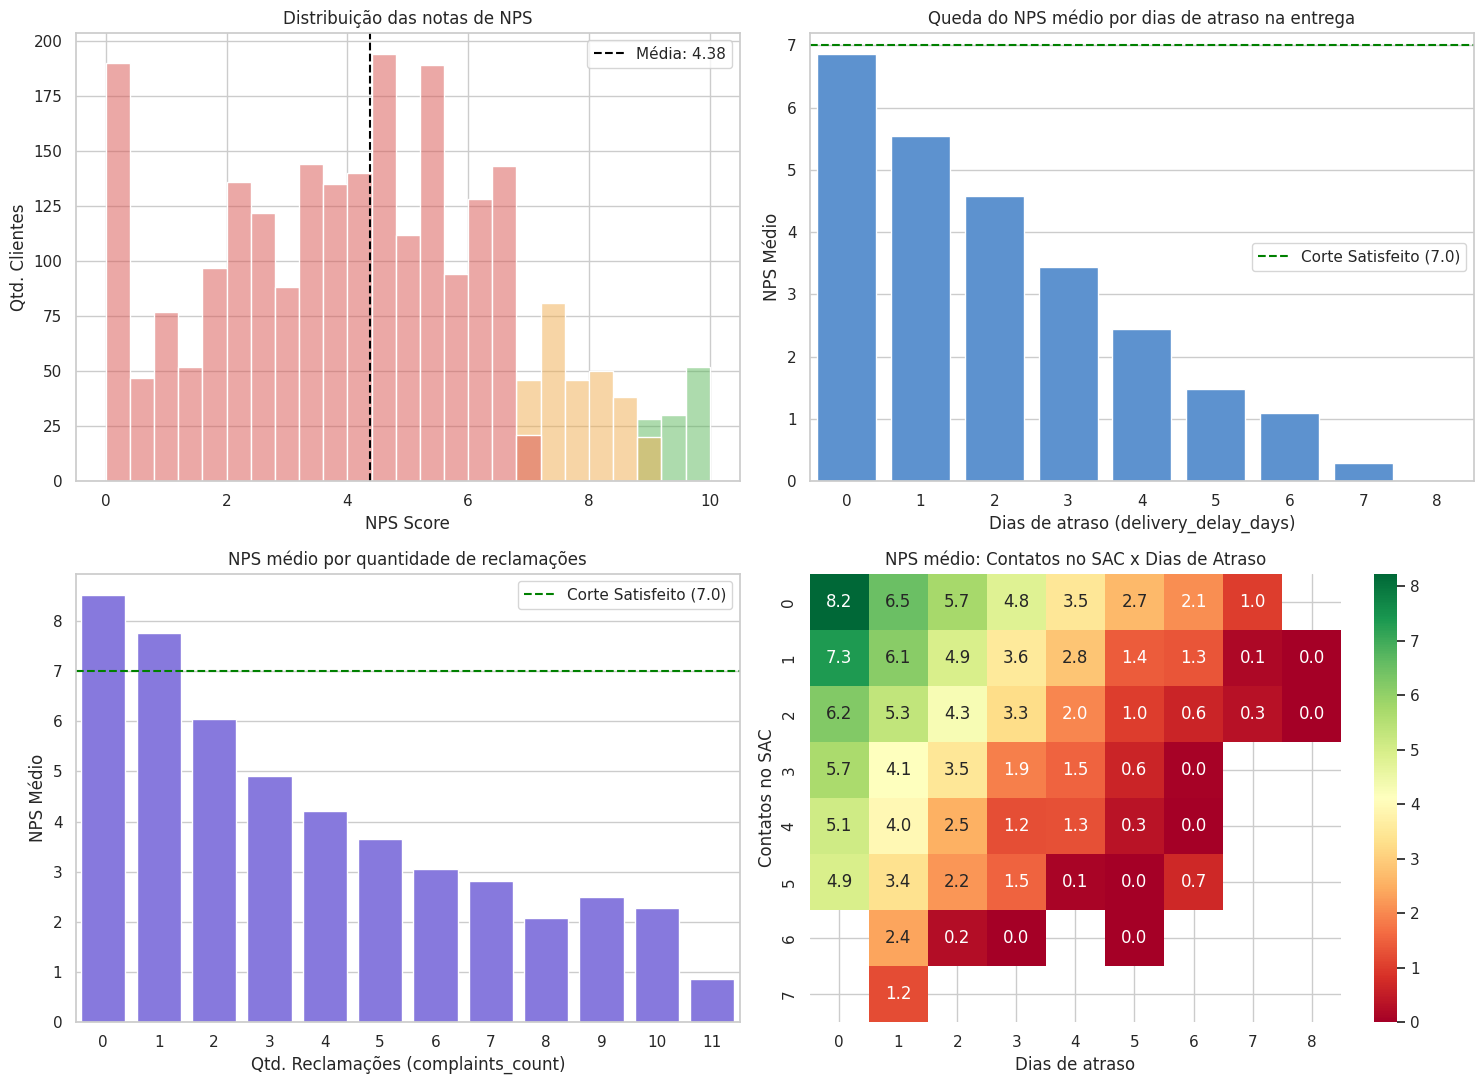

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Histograma do NPS
sns.histplot(
    data=df, x='nps_score', hue='faixa_nps',
    palette={'Detrator': '#d9534f', 'Neutro': '#f0ad4e', 'Promotor': '#5cb85c'},
    bins=25, ax=axes[0, 0]
)
axes[0, 0].axvline(df['nps_score'].mean(), color='black', linestyle='--', label=f"Média: {df['nps_score'].mean():.2f}")
axes[0, 0].set_title('Distribuição das notas de NPS')
axes[0, 0].set_xlabel('NPS Score')
axes[0, 0].set_ylabel('Qtd. Clientes')
axes[0, 0].legend()

# 2. Atraso na entrega vs NPS médio
sns.barplot(x=analise_atraso.index, y=analise_atraso['nps_medio'], color='#4a90e2', ax=axes[0, 1])
axes[0, 1].axhline(7.0, color='green', linestyle='--', label='Corte Satisfeito (7.0)')
axes[0, 1].set_title('Queda do NPS médio por dias de atraso na entrega')
axes[0, 1].set_xlabel('Dias de atraso (delivery_delay_days)')
axes[0, 1].set_ylabel('NPS Médio')
axes[0, 1].legend()

# 3. Quantidade de reclamações vs NPS médio
sns.barplot(x=analise_reclamacoes.index, y=analise_reclamacoes['nps_medio'], color='#7b68ee', ax=axes[1, 0])
axes[1, 0].axhline(7.0, color='green', linestyle='--', label='Corte Satisfeito (7.0)')
axes[1, 0].set_title('NPS médio por quantidade de reclamações')
axes[1, 0].set_xlabel('Qtd. Reclamações (complaints_count)')
axes[1, 0].set_ylabel('NPS Médio')
axes[1, 0].legend()

# 4. Heatmap combinando atraso e contatos no SAC
matriz_sac_atraso = df.pivot_table(
    index='customer_service_contacts',
    columns='delivery_delay_days',
    values='nps_score',
    aggfunc='mean'
)
sns.heatmap(matriz_sac_atraso, annot=True, fmt='.1f', cmap='RdYlGn', ax=axes[1, 1])
axes[1, 1].set_title('NPS médio: Contatos no SAC x Dias de Atraso')
axes[1, 1].set_xlabel('Dias de atraso')
axes[1, 1].set_ylabel('Contatos no SAC')

plt.tight_layout()
plt.show()

### Resumo da EDA (Visão para a Gestão de Operações)

Traduzindo os números acima de forma direta para a operação, sem termos estatísticos:

**1. Quais fatores são mais críticos para a satisfação?**
Um ponto super interessante da base é que o **tempo total de entrega prometido (`delivery_time_days`) tem correlação praticamente zero com o NPS (0,001)**. Ou seja, o cliente não dá nota baixa porque o prazo informado na compra era de 8 ou 12 dias; ele aceita esperar se o combinado for cumprido. O que derruba a nota são quatro problemas operacionais:
- **Atraso na entrega (`delivery_delay_days`):** é o maior vilão isolado (correlação de -0,60).
- **Volume de reclamações (`complaints_count`):** segundo fator mais forte (-0,50).
- **Contatos repetidos no SAC (`customer_service_contacts`):** quando o cliente precisa ir atrás da empresa várias vezes (-0,35).
- **Demora para resolver o chamado (`resolution_time_days`):** quanto mais dias o problema fica aberto, menor a nota (-0,19).

**2. O que mais gera detratores?**
A soma de **atraso logístico com atrito no atendimento**. Olhando a tabela de perfil, o cliente Promotor teve em média 0,72 dia de atraso, menos de 1 contato no SAC (0,67) e solução em 3,7 dias. Já o Detrator enfrentou em média 2,41 dias de atraso, registrou 4,44 reclamações e esperou quase 6 dias (5,69) para ter o caso resolvido.

**3. Existe algum "ponto de ruptura" na experiência do cliente?**
Sim, dá para cravar três limites bem claros onde a experiência desanda:
- **Na entrega (1º para o 2º dia de atraso):** Sem atraso (0 dias), o NPS médio fica em 6,86 e quase 34% dos clientes recompram em 30 dias. Com **1 dia de atraso**, a taxa de detratores já sobe de 51,6% para 74,0% e a recompra cai pela metade (14,8%). Com **2 dias de atraso**, 87,9% viram detratores e a recompra despenca para 4%. A partir de 5 dias de atraso, 100% da base é detratora.
- **Nas reclamações (a 2ª reclamação):** Clientes com 0 ou 1 reclamação mantêm NPS bom (8,52 e 7,77) e recompram bastante (69,6% e 42,6%). Quando o cliente chega na **2ª reclamação**, o NPS cai para 6,05 e o percentual de detratores mais que dobra (pula de 30,3% para 65,3%).
- **No SAC (a partir do 2º contato e 4º dia de resolução):** Precisar falar 2 vezes com o atendimento já joga a taxa de detratores para 88,6% (NPS médio de 4,12). No tempo de resolução, passando de 3 para 4 dias de espera, os detratores passam de 78% para quase 85%.

**4. Que tipo de cliente tende a ter NPS mais alto ou mais baixo?**
- **Idade, tempo de casa e região não mudam o jogo:** A idade média (~43 anos) e o tempo de relacionamento (~60 a 63 meses) são praticamente iguais nas três faixas de NPS. Entre as regiões (`customer_region`), o Sul tem a média um pouco maior (4,49) e o Centro-Oeste a menor (4,21), mas todas as regiões têm entre 83% e 85,5% de detratores. Isso mostra que o problema é da nossa operação como um todo, e não de um perfil demográfico específico.
- **Valor do pedido (`order_value`):** Os promotores têm um ticket médio um pouco maior (R$ 468 contra R$ 429 dos detratores), mas a diferença de nota vem mesmo de não sofrerem falhas na entrega.